# ARSET | Assessing Biodiversity Using Forest Structure from Spaceborne Lidar
## Part 2 – Demo 3: Linking GEDI Forest Structure with Bird and Mammal Diversity

**Goal:** Reproduce the core analysis of **Luther et al. (2026)**, *Satellite-based forest structure metrics as a predictive tool for biodiversity in hyperdiverse tropical forests* (Environmental and Sustainability Indicators 30: 101212). We test whether GEDI forest structure predicts bird and mammal occupancy at the Biological Dynamics of Forest Fragments Project (BDFFP), then interpret the model diagnostics and outputs.

**Tools:** Python (`pymc` + `numpyro` for Bayesian models, `statsmodels`, `pandas`, `matplotlib`) in Google Colab

**Data:** Luther et al. (2026) data and code, archived on Zenodo: *Scaling Biodiversity Monitoring with Spaceborne Lidar and Field Data*, [doi:10.5281/zenodo.24093269](https://doi.org/10.5281/zenodo.24093269) (CC BY 4.0)
- Daily detection/non-detection of **184 species from 31 AudioMoth recorders** and **41 species from 73 camera traps** (June–October 2022)
- GEDI forest-structure metrics for the **18 sampling units** with GEDI coverage (unit means of quality-filtered footprints, as produced in Demo 2)
- Acoustic space use (ASU) and observed species richness per sampling unit

**What you will do**
1. Load the in situ detection data and the site-level GEDI metrics
2. Check collinearity among GEDI metrics (why each metric gets its own model)
3. Quick look: does the soundscape (ASU) track species richness and forest structure?
4. Fit the **integrated community occupancy model** that combines audio and camera detections
5. Rank 12 GEDI predictors plus a null model with WAIC
6. Interpret community and species-level responses to FHD, and compare forest types

> **About the code:** The original analysis was run in R with `spOccupancy::intMsPGOcc()` (scripts shared by the authors). This notebook re-implements the same model structure in Python with PyMC, so participants do not need R. Priors and the sampler differ from `spOccupancy`, so numbers will be close to, but not identical with, the published values.

## 1. Setup

In [ ]:
!pip -q install pymc numpyro rdata

In [ ]:
import os
# Let JAX run one MCMC chain per CPU core (Colab has 2); must be set before JAX is imported
os.environ.setdefault("XLA_FLAGS", f"--xla_force_host_platform_device_count={os.cpu_count()}")

import itertools, re, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import rdata
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.special import expit, logsumexp

warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(logging.ERROR)   # we check convergence explicitly below
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import numpyro  # noqa: F401
    NUTS_SAMPLER = "numpyro"   # JAX-based sampler: much faster than the default
except ImportError:
    NUTS_SAMPLER = "pymc"
print("PyMC", pm.__version__, "| sampler:", NUTS_SAMPLER, "| Colab:", IN_COLAB)

PyMC 5.28.5 | sampler: numpyro | Colab: True


## 2. Parameters

In [ ]:
# --- Data: Luther et al. (2026) input files from Zenodo (doi:10.5281/zenodo.24093269, CC BY 4.0) ---
ZENODO_RECORD = "https://zenodo.org/records/24093269/files"
# local file name -> (file name on Zenodo, md5 checksum listed on the record)
DATA_FILES = {
    "y.full.rds":       ("y.full.rds",                        "7e6add496437988b59852ad063b1e7c4"),
    "occ.covs.rds":     ("occ.covs.rds",                      "8a347fbdd2f65fd11fe66e5e495f11d8"),
    "det.covs.rds":     ("det.covs.rds",                      "ad632551df2c8428d01c0b35d3874b0a"),
    "sp.indx.rds":      ("sp.indx.rds",                       "d5df6b1699c6dbb5c92206145eeb661f"),
    "points.indx.rds":  ("points.indx.rds",                   "a1b750da066d4851def96ce57817f57d"),
    "gedi_data.csv":    ("gedi data.csv",                     "5dcb1f890b9803bf2926c6311be81347"),
    "asu_data.csv":     ("asu data.csv",                      "50a22e00032bb8eebcd60168d0f10184"),
    # EltonTraits 1.0 bird diet data (Wilman et al. 2014), used for the foraging guilds in Section 8b
    "elton_birds.xlsx": ("EltonTraits bird guilds data.xlsx", "23c8c669114416c37f32d2909f3544f6"),
}
# EltonTraits 1.0 mammal diet data (Section 8b). Tried in order; the first that works is used.
# esapubs.org (the original host) blocks Colab with HTTP 403, so the figshare copy comes first.
ELTON_MAMMAL_URLS = [
    "https://ndownloader.figshare.com/files/5631084",                     # EltonTraits MamFuncDat.txt on figshare
    "https://esapubs.org/archive/ecol/E095/178/MamFuncDat.txt",          # original Ecological Archives copy
]
DATA_DIR = "luther2026_data"

# --- Model fitting ---
# FAST_MODE = True  -> live demo: fewer MCMC draws, and only 4 models are compared
#                      (null model + the 3 best GEDI metrics in Luther et al. 2026: FHD, RH95, AGBD)
# FAST_MODE = False -> full analysis: more draws, all 12 GEDI metrics + null model (13 models)
FAST_MODE = True
DRAWS, TUNE, CHAINS = (500, 1000, 2) if FAST_MODE else (1500, 1500, 4)
SEED = 2026

# Save fitted models so the live demo can reload them instead of refitting
MOUNT_DRIVE = False   # True = keep the model cache in Google Drive between sessions
CACHE_DIR = os.environ.get("ARSET_CACHE_DIR", "demo3_model_cache")
if MOUNT_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/ARSET_GEDI_Biodiversity/demo3_model_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# The 12 GEDI candidate predictors used by Luther et al. (2026) (column names in occ.covs.rds)
GEDI_CANDIDATES = ["fhd_mean", "rh_95_mean", "agbd_mean", "pavd_total_mean", "pai_total_mean", "cover_total_mean",
                   "pavd_15_mean", "pavd_25_mean", "cover_ratio_mean", "pavd_5_mean", "pavd_ratio_mean", "pai_ratio_mean"]
# FAST_MODE: the 3 best-performing metrics in Luther et al. (2026) Table 3 (the null model is always added)
FAST_CANDIDATES = ["fhd_mean", "rh_95_mean", "agbd_mean"]
LABELS = {"fhd_mean": "Foliage Height Diversity", "rh_95_mean": "Relative Height 95", "agbd_mean": "Above Ground Biomass",
          "pavd_total_mean": "Plant Area Volume Density total", "pai_total_mean": "Plant Area Index total",
          "cover_total_mean": "Cover total", "pavd_15_mean": "Plant Area Volume Density 15m",
          "pavd_25_mean": "Plant Area Volume Density 25m", "cover_ratio_mean": "Cover Ratio",
          "pavd_5_mean": "Plant Area Volume Density 5m", "pavd_ratio_mean": "Plant Area Volume Density ratio",
          "pai_ratio_mean": "Plant Area Index ratio", None: "Null Model"}

HABITAT_ORDER = ["1ha", "10ha", "100ha", "SF", "CF", "Lake"]
HABITAT_LABELS = {"1ha": "1 ha fragment", "10ha": "10 ha fragment", "100ha": "100 ha fragment",
                  "SF": "Secondary forest", "CF": "Continuous forest", "Lake": "Lake edge"}
HABITAT_COLORS = dict(zip(HABITAT_ORDER, ["#d95f02", "#e6ab02", "#a6761d", "#66a61e", "#1b5e20", "#1f78b4"]))

## 3. Load the data

| File | Contents |
|---|---|
| `y.full.rds` | Detection/non-detection arrays: `audio` (184 species × 31 recorders × 89 days) and `camtrap` (41 species × 73 cameras × 93 days); empty (`NA`) on days a device was not recording |
| `occ.covs.rds` | Occupancy covariates for all 104 devices: the 12 GEDI metrics of each device's sampling unit, standardized (mean 0, SD 1) |
| `det.covs.rds` | Detection covariate: standardized Julian date for each device and day |
| `sp.indx.rds`, `points.indx.rds` | Which species and which sites each data source covers |
| `gedi_data.csv` | Unstandardized GEDI unit means and land use for the 18 sampling units |
| `asu_data.csv` | Observed species richness and acoustic space use (ASU) for 15 sampling units |
| `elton_birds.xlsx` | EltonTraits 1.0 bird traits (Wilman et al. 2014): diet composition and the 5-category diet class (`Diet-5Cat`) for ~10,000 bird species |

All files are downloaded from the [Zenodo record](https://doi.org/10.5281/zenodo.24093269) and checked against its md5 checksums. Some are saved under shorter local names (e.g. `gedi data.csv` → `gedi_data.csv`). The `.rds` files are the exact inputs to the authors' R code; we read them directly with the `rdata` package. The record also holds the authors' R scripts (`integrated_community_occupancy_models.txt`, `species_occupancy_models.txt`).

In [ ]:
import hashlib
import urllib.parse
import requests


def md5sum(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


def zenodo_url(remote_name):
    return f"{ZENODO_RECORD}/{urllib.parse.quote(remote_name)}?download=1"


os.makedirs(DATA_DIR, exist_ok=True)
for name, (remote, md5) in DATA_FILES.items():
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and md5sum(path) == md5:
        print(f"  {name:16s} already downloaded")
        continue
    try:
        r = requests.get(zenodo_url(remote), timeout=120)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
        status = "ok" if md5sum(path) == md5 else "WARNING: md5 does not match the Zenodo record"
        print(f"  {name:16s} downloaded ({os.path.getsize(path) / 1024:.0f} KB, {status})")
    except Exception as err:
        print(f"  {name:16s} FAILED: {str(err)[:120]}")

missing = [f for f in DATA_FILES
           if not os.path.exists(os.path.join(DATA_DIR, f)) or os.path.getsize(os.path.join(DATA_DIR, f)) == 0]
if missing:
    print("\nSome files could not be downloaded. Download each file below from the Zenodo record, rename it to the "
          f"name on the left, drag it into the '{DATA_DIR}' folder in the Colab Files panel (left sidebar), "
          "then re-run this cell:")
    for f in missing:
        print(f"  {f}  <-  {zenodo_url(DATA_FILES[f][0])}")
    raise FileNotFoundError(f"Missing data files: {missing}")
print("Data folder:", os.path.abspath(DATA_DIR))


def _r_dataframe(obj, attrs):
    """R data.frames whose columns were standardized with scale() are stored as 1-column matrices: flatten them."""
    return pd.DataFrame({k: np.asarray(v).reshape(-1) for k, v in obj.items()})


def read_rds(name):
    return rdata.read_rds(os.path.join(DATA_DIR, name),
                          constructor_dict={**rdata.conversion.DEFAULT_CLASS_MAP, "data.frame": _r_dataframe,
                                            "tbl_df": _r_dataframe, "tbl": _r_dataframe})


y_full = read_rds("y.full.rds")          # dict: audio / camtrap -> xarray (species, device, day)
occ = read_rds("occ.covs.rds")           # 104 devices × GEDI covariates (standardized)
det_covs = read_rds("det.covs.rds")      # dict: audio / camtrap -> julian_std (device × day)
sp_index = read_rds("sp.indx.rds")       # dict: species names per data source
pt_index = read_rds("points.indx.rds")   # dict: occupancy-site index (1-based) per data source
gedi = pd.read_csv(os.path.join(DATA_DIR, "gedi_data.csv"))
asu = pd.read_csv(os.path.join(DATA_DIR, "asu_data.csv")).rename(columns={"biodiversity sites": "site"})

SOURCES = {"audio": "AudioMoth recorders", "camtrap": "Camera traps"}
for m, label in SOURCES.items():
    a = y_full[m].values
    print(f"{label:>20}: {a.shape[0]} species × {a.shape[1]} devices × {a.shape[2]} days | "
          f"{int(np.isfinite(a[0]).sum()):,} device-days surveyed | {int(np.nansum(a)):,} detections")
species = sorted(set(sp_index["audio"]) | set(sp_index["camtrap"]))
print(f"{len(species)} species in total; {len(set(sp_index['audio']) & set(sp_index['camtrap']))} detected by both methods")

  y.full.rds       downloaded (31 KB)
  occ.covs.rds     downloaded (4 KB)
  det.covs.rds     downloaded (4 KB)
  sp.indx.rds      downloaded (2 KB)
  points.indx.rds  downloaded (0 KB)
  gedi_data.csv    downloaded (2 KB)
  asu_data.csv     downloaded (1 KB)
Data folder: /content/luther2026_data
 AudioMoth recorders: 184 species × 31 devices × 89 days | 769 device-days surveyed | 5,306 detections
        Camera traps: 41 species × 73 devices × 93 days | 1,818 device-days surveyed | 685 detections
212 species in total; 13 detected by both methods


### Sampling units, habitat and observed richness
Each device belongs to a sampling unit (e.g. `d-100a` = Dimona 100 ha fragment, location A). Land use comes from `gedi_data.csv`.

In [ ]:
HABITAT_MAP = {"1HA": "1ha", "10HA": "10ha", "100HA": "100ha", "SF": "SF", "CF": "CF", "LAKE": "Lake"}
gedi["unit"] = gedi["Sites"].str.lower()
gedi["habitat"] = pd.Categorical(gedi["Land_Use"].str.upper().map(HABITAT_MAP), HABITAT_ORDER, ordered=True)
occ = occ.merge(gedi[["unit", "habitat"]], left_on="site", right_on="unit", how="left")

# Observed (naive) richness per unit: species detected at least once by any device in the unit
rows = []
for m in SOURCES:
    arr = y_full[m]
    detected = np.nan_to_num(arr.values).sum(axis=2) > 0          # species × device
    for j, dev in enumerate(arr.coords[arr.dims[1]].values):
        unit = str(dev).rsplit("-", 1)[0]
        rows += [(unit, m, s) for s in np.asarray(arr.coords[arr.dims[0]].values)[detected[:, j]]]
obs = pd.DataFrame(rows, columns=["unit", "method", "species"])
units = (gedi[["unit", "habitat"]]
         .merge(obs.groupby("unit")["species"].nunique().rename("obs_richness"), on="unit", how="left")
         .merge(occ.groupby("unit").size().rename("n_devices"), on="unit"))
print(f"Mean species detected per unit: {units['obs_richness'].mean():.1f}")
PAPER_RICH = {"100ha": 98, "CF": 82.2, "10ha": 72.5, "SF": 71, "1ha": 46, "Lake": 37.5}   # Luther et al. (2026), Sec. 3.1
rich_tab = units.groupby("habitat", observed=True)["obs_richness"].agg(["mean", "min", "max", "count"]).round(1)
rich_tab["paper mean"] = rich_tab.index.map(PAPER_RICH)
rich_tab

Mean species detected per unit: 68.8


,mean,min,max,count,paper mean
habitat,,,,,
1ha,46.0,28,61,3,46.0
10ha,72.5,66,79,2,72.5
100ha,98.0,97,99,2,98.0
SF,71.0,54,83,5,71.0
CF,82.2,72,93,4,82.2
Lake,37.5,35,40,2,37.5


## 4. GEDI forest structure across habitats, and collinearity

Luther et al. found continuous forest (CF) was tallest, had the highest FHD and the most biomass. Fragments had the highest PAVD and PAI ratios (more plant material in the upper canopy).

In [ ]:
raw_cols = {"RH_95_mean": "RH95 (m)", "FHD_mean": "FHD", "AGBD_mean": "AGBD (Mg/ha)", "pai_total_mean": "PAI",
            "pavd_ratio_mean": "PAVD ratio", "pai_ratio_mean": "PAI ratio"}
gedi.groupby("habitat", observed=True)[list(raw_cols)].mean().rename(columns=raw_cols).round(2)

,RH95 (m),FHD,AGBD (Mg/ha),PAI,PAVD ratio,PAI ratio
habitat,,,,,,
1ha,18.60,2.76,111.61,3.42,3.04,2.90
10ha,18.21,2.72,133.95,3.03,3.35,2.79
100ha,22.24,3.01,147.04,4.10,3.37,2.99
SF,21.75,2.99,165.76,4.45,2.13,1.97
CF,24.35,3.10,237.52,3.95,2.58,2.32
Lake,16.42,2.72,65.00,2.98,3.37,2.79


GEDI metrics are derived from the same waveform (PAI, cover and PAVD are calculated from each other), so many are strongly correlated. Most pairs exceed |r| = 0.6. **That is why each GEDI metric gets its own occupancy model**, and model selection decides which one predicts best.

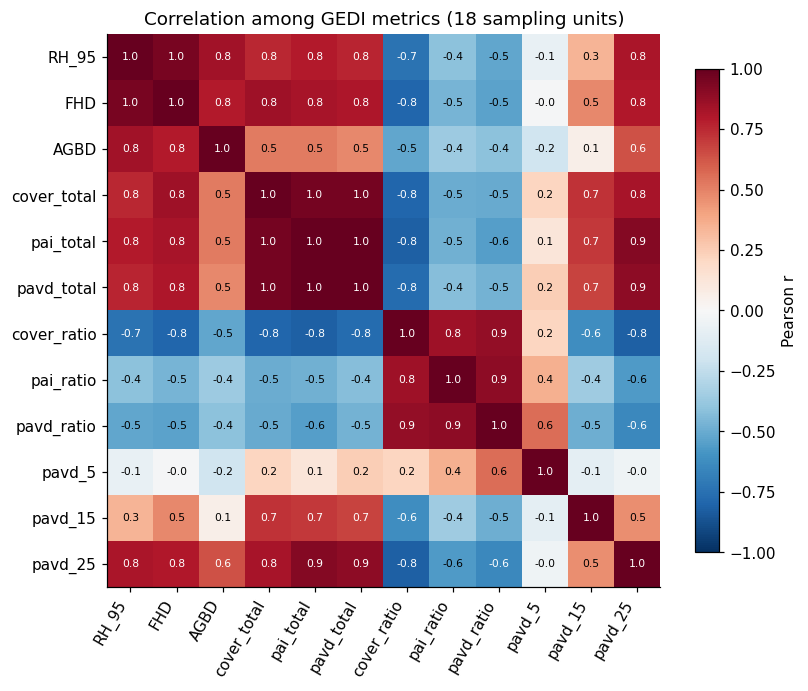

32 of 66 metric pairs have |r| > 0.6
FHD_mean          13.4
RH_95_mean        15.6
AGBD_mean          4.6
pai_total_mean     4.3
pai_ratio_mean     1.4


In [ ]:
metric_cols = ["RH_95_mean", "FHD_mean", "AGBD_mean", "cover_total_mean", "pai_total_mean", "pavd_total_mean",
               "cover_ratio_mean", "pai_ratio_mean", "pavd_ratio_mean", "pavd_5_mean", "pavd_15_mean", "pavd_25_mean"]
corr = gedi[metric_cols].corr()
short = [c.replace("_mean", "") for c in metric_cols]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(short)), short, rotation=60, ha="right")
ax.set_yticks(range(len(short)), short)
for i in range(len(short)):
    for j in range(len(short)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation among GEDI metrics (18 sampling units)")
plt.tight_layout()
plt.show()

pairs = [(a, b) for a, b in itertools.combinations(metric_cols, 2) if abs(corr.loc[a, b]) > 0.6]
print(f"{len(pairs)} of {len(metric_cols) * (len(metric_cols) - 1) // 2} metric pairs have |r| > 0.6")
vif_set = ["FHD_mean", "RH_95_mean", "AGBD_mean", "pai_total_mean", "pai_ratio_mean"]
Xv = (gedi[vif_set] - gedi[vif_set].mean()) / gedi[vif_set].std()
Xv.insert(0, "const", 1.0)
print(pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=vif_set, name="VIF").round(1).to_string())

## 5. Quick look: the soundscape as a biodiversity proxy

Acoustic space use (ASU) is the share of time–frequency bins with sound. It is fast to compute and needs no species identification. Luther et al. found that **mid-frequency ASU (2–8 kHz, mostly birds, amphibians and primates)** tracked species richness, and that ASU increased with FHD. We reproduce their regressions (Table 2) for the 15 units with soundscape data.

In [ ]:
sa = asu.merge(gedi, left_on="site", right_on="unit")
fits = {
    "ASU_all ~ FHD + PAI_ratio": smf.ols("ASU_all ~ FHD_mean + pai_ratio_mean", sa).fit(),
    "ASU_high ~ FHD + PAI_ratio": smf.ols("ASU_high ~ FHD_mean + pai_ratio_mean", sa).fit(),
    "ASU_low ~ FHD + PAI": smf.ols("ASU_low ~ FHD_mean + pai_total_mean", sa).fit(),
    "ASU_med ~ FHD + PAI_ratio": smf.ols("ASU_med ~ FHD_mean + pai_ratio_mean", sa).fit(),
}
paper_r2 = {"ASU_all ~ FHD + PAI_ratio": 0.126, "ASU_high ~ FHD + PAI_ratio": 0.078,
            "ASU_low ~ FHD + PAI": 0.473, "ASU_med ~ FHD + PAI_ratio": 0.302}
t2 = pd.concat({k: pd.DataFrame({"Estimate": m.params, "Std. Error": m.bse, "t": m.tvalues, "p": m.pvalues})
                for k, m in fits.items()})
t2["adj. R²"] = [fits[k].rsquared_adj if term == "Intercept" else np.nan for k, term in t2.index]
t2["paper R²"] = [paper_r2[k] if term == "Intercept" else np.nan for k, term in t2.index]
t2.round(3).fillna("")

Estimate  Std. Error      t      p  \
ASU_all ~ FHD + PAI_ratio  Intercept          0.196       0.261  0.749  0.468   
                           FHD_mean           0.114       0.075  1.529  0.152   
                           pai_ratio_mean    -0.016       0.032 -0.508  0.621   
ASU_high ~ FHD + PAI_ratio Intercept          0.213       0.357  0.595  0.563   
                           FHD_mean           0.121       0.102  1.179  0.261   
                           pai_ratio_mean    -0.030       0.043 -0.700  0.497   
ASU_low ~ FHD + PAI        Intercept         -0.777       0.238 -3.269  0.007   
                           FHD_mean           0.429       0.113  3.802  0.003   
                           pai_total_mean    -0.093       0.031 -2.977  0.012   
ASU_med ~ FHD + PAI_ratio  Intercept          0.351       0.103  3.394  0.005   
                           FHD_mean           0.082       0.030  2.759  0.017   
                           pai_ratio_mean     0.007       0.013  0.584  0.570   

                                          adj. R² paper R²  
ASU_all ~ FHD + PAI_ratio  Intercept        0.126    0.126  
                           FHD_mean                         
                           pai_ratio_mean                   
ASU_high ~ FHD + PAI_ratio Intercept        0.078    0.078  
                           FHD_mean                         
                           pai_ratio_mean                   
ASU_low ~ FHD + PAI        Intercept        0.473    0.473  
                           FHD_mean                         
                           pai_total_mean                   
ASU_med ~ FHD + PAI_ratio  Intercept        0.302    0.302  
                           FHD_mean                         
                           pai_ratio_mean

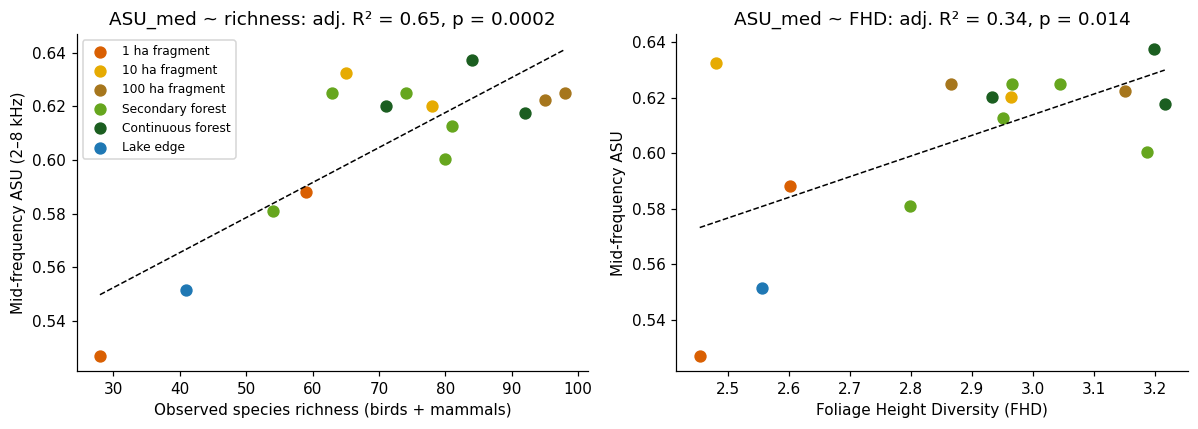

In [ ]:
m_rich = smf.ols("ASU_med ~ sp_richness", sa).fit()
m_fhd = smf.ols("ASU_med ~ FHD_mean", sa).fit()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for h in HABITAT_ORDER:
    d = sa[sa["habitat"] == h]
    axes[0].scatter(d["sp_richness"], d["ASU_med"], color=HABITAT_COLORS[h], label=HABITAT_LABELS[h], s=50)
    axes[1].scatter(d["FHD_mean"], d["ASU_med"], color=HABITAT_COLORS[h], s=50)
for ax, m, xcol in [(axes[0], m_rich, "sp_richness"), (axes[1], m_fhd, "FHD_mean")]:
    xs = np.linspace(sa[xcol].min(), sa[xcol].max(), 50)
    ax.plot(xs, m.predict(pd.DataFrame({xcol: xs})), "k--", lw=1)
axes[0].set(xlabel="Observed species richness (birds + mammals)", ylabel="Mid-frequency ASU (2–8 kHz)",
            title=f"ASU_med ~ richness: adj. R² = {m_rich.rsquared_adj:.2f}, p = {m_rich.pvalues.iloc[1]:.4f}")
axes[1].set(xlabel="Foliage Height Diversity (FHD)", ylabel="Mid-frequency ASU",
            title=f"ASU_med ~ FHD: adj. R² = {m_fhd.rsquared_adj:.2f}, p = {m_fhd.pvalues.iloc[1]:.3f}")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. The integrated community occupancy model

Detections are imperfect: a species can be present but missed. An **occupancy model** separates *where a species occurs* from *whether we detected it*. The **community** (multispecies) version shares information across species through community-level distributions. The **integrated** version combines two data sources, recorders and cameras, each with its own detection process. Each device is a site.

For species *i* at site (device) *j* on day *k*:

$$z_{ij} \sim \text{Bernoulli}(\psi_{ij}), \qquad \text{logit}(\psi_{ij}) = \beta_{0i} + \beta_{1i}\,\text{GEDI}_{j}$$

$$y_{ijk} \sim \text{Bernoulli}(p_{ijk}\, z_{ij}), \qquad \text{logit}(p_{ijk}) = \alpha_{0i} + \alpha_{1i}\,\text{Julian}_{jk} + \alpha_{2i}\,\text{Julian}^2_{jk}\quad\text{(separately for audio and cameras)}$$

Species coefficients come from community distributions, e.g. $\beta_{1i} \sim N(\mu_{\beta_1}, \sigma_{\beta_1})$. **The community mean $\mu_{\beta_1}$ is the key quantity:** the average effect of forest structure on occupancy across all 212 species.

The authors' R code for the same model:
```r
intMsPGOcc(occ.formula = ~ fhd_mean,
           det.formula = list(audio   = ~ julian_std + I(julian_std^2),
                              camtrap = ~ julian_std + I(julian_std^2)),
           data = list(y = y.full, occ.covs = occ.covs, det.covs = det.covs,
                       sites = points.indx, species = sp.indx),
           n.samples = 25000, n.burn = 15000, n.thin = 10, n.chains = 3)
```
Here the latent $z$ is summed out of the likelihood, so the fast NUTS sampler can be used. That gives good convergence with far fewer draws than the Gibbs sampler in `spOccupancy`.

In [ ]:
sp_pos = {s: i for i, s in enumerate(species)}
DATA = {}
for m in SOURCES:
    arr = y_full[m].values                                   # species × device × day, NaN = not surveyed
    jul = det_covs[m]["julian_std"].values                   # device × day
    J = np.where(np.isfinite(jul), jul, 0.0)
    yy = np.nan_to_num(arr)
    DATA[m] = dict(
        # Days with detections enter the likelihood only through these sums, because log p − log(1 − p) = logit(p)
        Y0=yy.sum(2), Y1=(yy * J[None]).sum(2), Y2=(yy * J[None] ** 2).sum(2),
        any_det=yy.sum(2) > 0,
        E=np.isfinite(arr[0]).astype(float),                 # survey effort: device × day (same for all species)
        dates_z=np.nanmean(jul, axis=0),                     # standardized Julian date of each day
        sp=np.array([sp_pos[s] for s in sp_index[m]]),       # species of this source -> position in full list
        site=np.asarray(pt_index[m]) - 1,                    # devices of this source -> row of occ (0-based)
    )


def log_sigmoid(x):
    return -pm.math.log1pexp(-x)


def site_loglik(logit_psi, coef, a):
    """Log-likelihood per (species, device), summing out the latent occupancy state z."""
    c0, c1, c2 = coef
    D = a["dates_z"][None, :]
    log_q = log_sigmoid(-(c0[:, None] + c1[:, None] * D + c2[:, None] * D ** 2))    # log(1 − p) per species × day
    ll_det = (pt.dot(log_q, a["E"].T)                                              # all surveyed days as misses
              + c0[:, None] * a["Y0"] + c1[:, None] * a["Y1"] + c2[:, None] * a["Y2"])  # + logit(p) on detection days
    lpsi, l1mpsi = log_sigmoid(logit_psi), log_sigmoid(-logit_psi)
    return pt.switch(a["any_det"], lpsi + ll_det, pt.logaddexp(lpsi + ll_det, l1mpsi))


def community(name, dims, mu_sd=1.65, sd_sd=1.5):
    """Species coefficients drawn from a community normal distribution (non-centered).
    mu_sd = 1.65 matches spOccupancy's default N(0, 2.72) prior on community means."""
    mu = pm.Normal(f"mu_{name}", 0, mu_sd)
    sd = pm.HalfNormal(f"sd_{name}", sd_sd)
    return pm.Deterministic(name, mu + sd * pm.Normal(f"{name}_z", 0, 1, dims=dims), dims=dims)


def build_model(metric=None):
    coords = {"species": species, "sp_audio": list(sp_index["audio"]), "sp_camtrap": list(sp_index["camtrap"])}
    x = occ[metric].values if metric else None
    with pm.Model(coords=coords) as model:
        b0 = community("b0", "species")
        b1 = community("b1", "species") if metric else None
        for m, a in DATA.items():
            dims = f"sp_{m}"
            coef = (community(f"a0_{m}", dims), community(f"a1_{m}", dims), community(f"a2_{m}", dims))
            s = a["sp"]
            logit_psi = b0[s][:, None] + (b1[s][:, None] * x[a["site"]][None, :] if metric else 0)
            pm.Potential(f"loglik_{m}", site_loglik(logit_psi, coef, a).sum())
    return model


def fit(metric=None):
    """Fit (or reload from cache) the occupancy model with one GEDI covariate (None = null model)."""
    name = metric or "null"
    path = os.path.join(CACHE_DIR, f"luther2026_{name}_{DRAWS}x{CHAINS}_t{TUNE}.nc")
    if os.path.exists(path):
        return az.from_netcdf(path)
    t0 = time.time()
    with build_model(metric):
        idata = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, target_accept=0.9, random_seed=SEED,
                          nuts_sampler=NUTS_SAMPLER, progressbar=False,
                          nuts_sampler_kwargs={"chain_method": "parallel"} if NUTS_SAMPLER == "numpyro" else {})
    idata.to_netcdf(path)
    print(f"  {name}: fitted in {time.time() - t0:.0f} s")
    return idata

### Fit the FHD model and check convergence

Before interpreting a Bayesian model, check that the MCMC chains converged:
- **R-hat ≈ 1.00** (values > 1.05 mean the chains disagree, so run longer)
- **Effective sample size (ESS)** large enough (rule of thumb > 400 for key parameters)
- **Trace plots** that look like overlapping "fuzzy caterpillars"

> **Presenter note – runtime:** each model takes about 3–4 minutes on a standard Colab CPU. `FAST_MODE` fits 4 models (about 15 minutes); the full 13-model comparison takes about 1–1.5 hours. Run the notebook once before the session with `MOUNT_DRIVE = True` so the fitted models are saved to Google Drive. They then load in seconds during the live demo.

In [ ]:
idata_fhd = fit("fhd_mean")
comm_vars = ["mu_b0", "sd_b0", "mu_b1", "sd_b1", "mu_a0_audio", "mu_a1_audio", "mu_a2_audio",
             "mu_a0_camtrap", "mu_a1_camtrap", "mu_a2_camtrap"]
summary = az.summary(idata_fhd, var_names=comm_vars, hdi_prob=0.95)
display(summary[["mean", "sd", "hdi_2.5%", "hdi_97.5%", "ess_bulk", "r_hat"]].round(3))
rhat = az.rhat(idata_fhd, var_names=["b0", "b1"])
print(f"Species-level occupancy parameters with R-hat > 1.05: "
      f"{int((rhat['b0'] > 1.05).sum() + (rhat['b1'] > 1.05).sum())} of {2 * len(species)}")
print(f"Mean occupancy across species: {expit(idata_fhd.posterior['b0'].values).mean():.3f} (paper: 0.337)")

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


  fhd_mean: fitted in 483 s


,mean,sd,hdi_2.5%,hdi_97.5%,ess_bulk,r_hat
mu_b0,-0.809,0.128,-1.036,-0.534,185.0,1.00
sd_b0,1.344,0.097,1.150,1.528,456.0,1.00
mu_b1,0.211,0.060,0.083,0.317,915.0,1.00
sd_b1,0.533,0.069,0.407,0.671,394.0,1.00
mu_a0_audio,-2.832,0.112,-3.064,-2.631,282.0,1.01
mu_a1_audio,0.143,0.066,0.012,0.267,174.0,1.01
mu_a2_audio,-0.107,0.063,-0.220,0.017,445.0,1.00
mu_a0_camtrap,-4.240,0.245,-4.692,-3.749,392.0,1.01
mu_a1_camtrap,-0.133,0.070,-0.258,0.015,974.0,1.00
mu_a2_camtrap,0.073,0.102,-0.116,0.271,1071.0,1.00


Species-level occupancy parameters with R-hat > 1.05: 0 of 424
Mean occupancy across species: 0.350 (paper: 0.337)


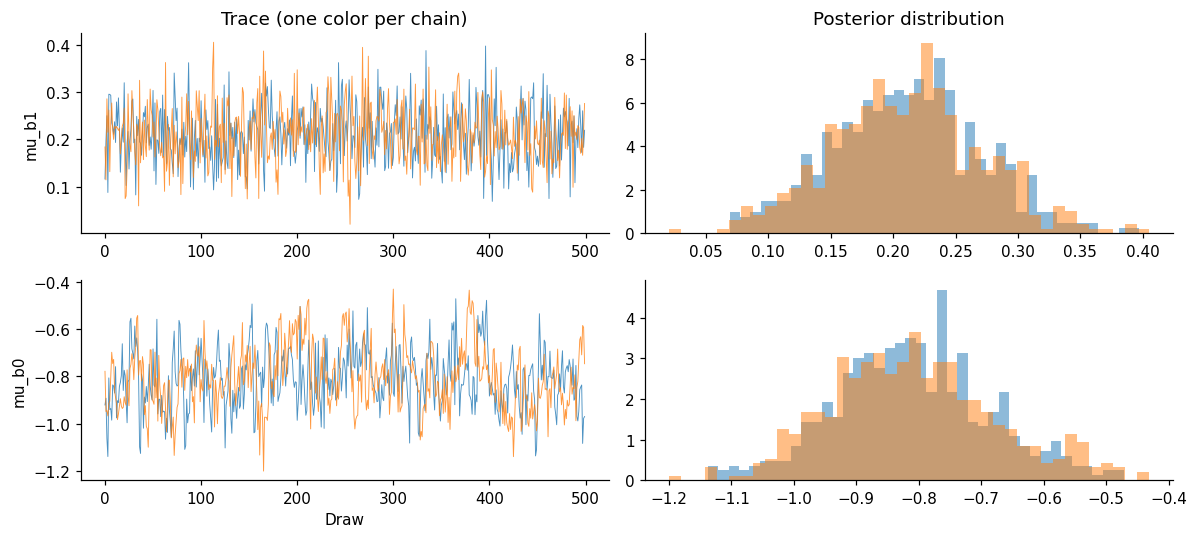

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5))
post = idata_fhd.posterior
for row, var in enumerate(["mu_b1", "mu_b0"]):
    for c in post.chain.values:
        v = post[var].sel(chain=c).values
        axes[row, 0].plot(v, lw=0.6, alpha=0.8)
        axes[row, 1].hist(v, bins=40, alpha=0.5, density=True)
    axes[row, 0].set_ylabel(var)
axes[0, 0].set_title("Trace (one color per chain)")
axes[0, 1].set_title("Posterior distribution")
axes[1, 0].set_xlabel("Draw")
plt.tight_layout()
plt.show()

## 7. Which GEDI metric best predicts occupancy? (WAIC model ranking)

We fit one model per GEDI metric plus a null model and compare them with **WAIC** (Widely Applicable Information Criterion). **Lower WAIC -> better predictive performance.** A difference of more than about 4 is meaningful.

$$\text{WAIC} = -2\,(\text{lppd} - p_\text{WAIC})$$

lppd is the log pointwise predictive density (model fit; called *elpd* in `spOccupancy` and the paper) and $p_\text{WAIC}$ the effective number of parameters (complexity penalty, *pD* in the paper). Like `spOccupancy`, we compute WAIC per species and site, so our values can be compared directly with the paper's Table 3. Small differences come from the priors and the MCMC sample. In `FAST_MODE` we compare only 4 models with fewer draws: the null model plus the three metrics that ranked best in the paper (FHD, RH95, AGBD). With fewer draws WAIC carries some Monte Carlo noise, so models less than ~10 WAIC apart may swap places between runs. Set `FAST_MODE = False` to fit all 13 models for final numbers.

In [ ]:
def log_sig_np(x):
    return -np.logaddexp(0, -x)


def pointwise_loglik(idata, metric):
    """Log-likelihood for every (species, device) and posterior draw: shape (draws, observations)."""
    p = idata.posterior
    n = p.sizes["chain"] * p.sizes["draw"]
    flat = lambda v: p[v].values.reshape(n, *p[v].shape[2:])
    b0 = flat("b0")
    b1 = flat("b1") if metric else np.zeros_like(b0)
    x = occ[metric].values if metric else np.zeros(len(occ))
    out = []
    for m, a in DATA.items():
        lp = b0[:, a["sp"], None] + b1[:, a["sp"], None] * x[a["site"]][None, None, :]
        c0, c1, c2 = flat(f"a0_{m}"), flat(f"a1_{m}"), flat(f"a2_{m}")
        D = a["dates_z"][None, None, :]
        log_q = log_sig_np(-(c0[..., None] + c1[..., None] * D + c2[..., None] * D ** 2))
        ldet = log_q @ a["E"].T + c0[..., None] * a["Y0"] + c1[..., None] * a["Y1"] + c2[..., None] * a["Y2"]
        lpsi, l1m = log_sig_np(lp), log_sig_np(-lp)
        ll = np.where(a["any_det"][None], lpsi + ldet, np.logaddexp(lpsi + ldet, l1m))
        out.append(ll.reshape(n, -1))
    return np.concatenate(out, axis=1)


def waic(idata, metric):
    ll = pointwise_loglik(idata, metric)
    lppd = np.sum(logsumexp(ll, axis=0) - np.log(ll.shape[0]))
    p_waic = np.sum(np.var(ll, axis=0, ddof=1))
    return dict(lppd=lppd, p_waic=p_waic, WAIC=-2 * (lppd - p_waic))


PAPER_T3 = pd.DataFrame({  # Luther et al. (2026) Table 3
    "model": ["Foliage Height Diversity", "Relative Height 95", "Above Ground Biomass", "Plant Area Volume Density total",
              "Plant Area Index total", "Cover total", "Plant Area Volume Density 15m", "Plant Area Volume Density 25m",
              "Null Model", "Cover Ratio", "Plant Area Volume Density 5m", "Plant Area Volume Density ratio",
              "Plant Area Index ratio"],
    "paper elpd": [-18191.401, -18210.525, -18227.055, -18248.095, -18251.421, -18231.93, -18270.739, -18271.485,
                   -18310.218, -18277.6, -18290.722, -18293.223, -18295.515],
    "paper pD": [987.07, 975.43, 974.307, 959.522, 956.711, 976.472, 949.819, 949.839, 913.435, 948.101, 935.353,
                 936.283, 935.107],
    "paper WAIC": [38356.941, 38371.910, 38402.725, 38415.233, 38416.264, 38416.805, 38441.115, 38442.649, 38447.306,
                   38451.402, 38452.151, 38459.012, 38461.244]})
PAPER_RANK = ["Foliage Height Diversity", "Relative Height 95", "Above Ground Biomass", "Plant Area Volume Density total",
              "Plant Area Index total", "Cover total", "Plant Area Volume Density 15m", "Plant Area Volume Density 25m",
              "Null Model", "Cover Ratio", "Plant Area Volume Density 5m", "Plant Area Volume Density ratio",
              "Plant Area Index ratio"]
candidates = [None] + (FAST_CANDIDATES if FAST_MODE else GEDI_CANDIDATES)
fits_occ = {"fhd_mean": idata_fhd}
rows = []
for metric in candidates:
    key = metric or "null"
    if key not in fits_occ:
        fits_occ[key] = fit(metric)
    rows.append(dict(model=LABELS[metric], **waic(fits_occ[key], metric)))
table = pd.DataFrame(rows).sort_values("WAIC").reset_index(drop=True)
table["ΔWAIC"] = table["WAIC"] - table["WAIC"].min()
table["paper rank"] = table["model"].map({m: i + 1 for i, m in enumerate(PAPER_RANK)})
table = table.merge(PAPER_T3, on="model", how="left")
table.round(1)

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


  null: fitted in 353 s


ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


  rh_95_mean: fitted in 458 s


ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


  agbd_mean: fitted in 441 s


,model,lppd,p_waic,WAIC,ΔWAIC,paper rank,paper elpd,paper pD,paper WAIC
0,Relative Height 95,-18195.5,986.6,38364.1,0.0,2,-18210.5,975.4,38371.9
1,Foliage Height Diversity,-18185.1,999.4,38369.2,5.0,1,-18191.4,987.1,38356.9
2,Above Ground Biomass,-18213.4,990.9,38408.7,44.6,3,-18227.1,974.3,38402.7
3,Null Model,-18312.3,921.3,38467.3,103.2,9,-18310.2,913.4,38447.3


**Published ranking (Luther et al. 2026, Table 3):** FHD (best) > RH95 > AGBD > PAVD total > PAI total > Cover total > PAVD 15m > PAVD 25m > **Null** > Cover ratio > PAVD 5m > PAVD ratio > PAI ratio.

*Discussion prompt:* Several structure metrics beat the null model, but FHD, which measures **vertical heterogeneity**, ranked first. Why would heterogeneity matter more than total foliage (PAI) or biomass (AGBD)?

## 8. Interpreting the best model

### 8a. Community-level response (cf. Luther et al. Fig. 2)
The paper reports that average occupancy roughly **doubled along the FHD gradient (0.17 → 0.36)**.

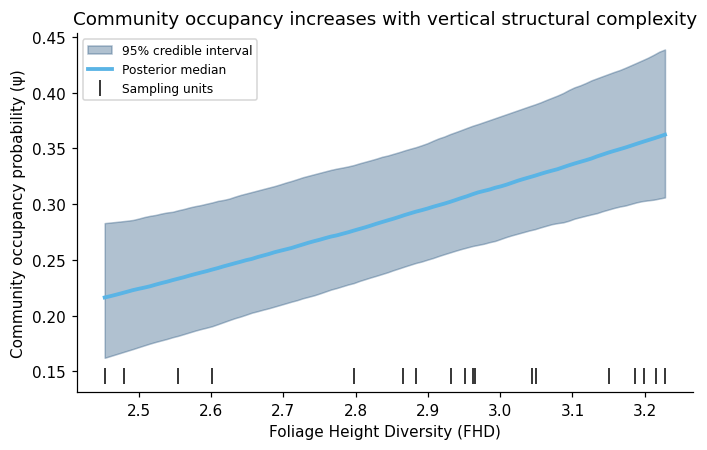

Community occupancy: 0.22 at lowest FHD → 0.36 at highest FHD  (paper: 0.17 → 0.36)
P(mu_b1 > 0) = 1.000  (posterior probability that FHD has a positive community effect)


In [ ]:
# Covariates were standardized across the 104 devices: recover the FHD scale for plotting
fhd_raw = occ.merge(gedi[["unit", "FHD_mean"]], on="unit")["FHD_mean"].values
fhd_mu, fhd_sd = fhd_raw.mean(), fhd_raw.std(ddof=1)
grid = np.linspace(fhd_raw.min(), fhd_raw.max(), 100)
gz = (grid - fhd_mu) / fhd_sd

p = idata_fhd.posterior
mu_b0, mu_b1 = p["mu_b0"].values.ravel(), p["mu_b1"].values.ravel()
psi = expit(mu_b0[:, None] + mu_b1[:, None] * gz[None, :])
lo, mid, hi = np.percentile(psi, [2.5, 50, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.fill_between(grid, lo, hi, color="#1f4e79", alpha=0.35, label="95% credible interval")
ax.plot(grid, mid, color="#5ab4e5", lw=2.5, label="Posterior median")
ax.plot(np.unique(fhd_raw), np.full(len(np.unique(fhd_raw)), lo.min() * 0.9), "|", color="k", ms=10,
        label="Sampling units")
ax.set(xlabel="Foliage Height Diversity (FHD)", ylabel="Community occupancy probability (ψ)",
       title="Community occupancy increases with vertical structural complexity")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
print(f"Community occupancy: {mid[0]:.2f} at lowest FHD → {mid[-1]:.2f} at highest FHD  (paper: 0.17 → 0.36)")
print(f"P(mu_b1 > 0) = {(mu_b1 > 0).mean():.3f}  (posterior probability that FHD has a positive community effect)")

### 8b. Species-level responses by foraging guild (cf. Luther et al. Fig. 3)
Like the paper, we assign foraging guilds from **EltonTraits 1.0** (Wilman et al. 2014). A diet category is assigned when it makes up **more than 50%** of the diet, otherwise the species is an omnivore.
- **Birds** (184 species) come from the EltonTraits bird table downloaded in Section 3 (`elton_birds.xlsx`), using its published 5-category diet class (`Diet-5Cat`).
- **Mammals** (28 species) come from the EltonTraits mammal table, downloaded here from figshare. If the download fails, download `MamFuncDat.txt` yourself, rename it `elton_mammals.txt`, put it in the data folder and re-run the cell.

Some names changed since 2014, so a short synonym list maps current names to EltonTraits names. Any remaining species are matched by genus when all EltonTraits species in that genus share a guild.

In [ ]:
ELTON_BIRDS_FILE = os.path.join(DATA_DIR, "elton_birds.xlsx")     # downloaded in Section 3
ELTON_MAMMALS_FILE = os.path.join(DATA_DIR, "elton_mammals.txt")  # downloaded below (or added by hand)
SYNONYMS = {  # current name -> name(s) used in EltonTraits 1.0
    "Cercomacroides tyrannina": ["Cercomacra tyrannina"], "Tunchiornis ochraceiceps": ["Hylophilus ochraceiceps"],
    "Pachysylvia muscicapina": ["Hylophilus muscicapinus"], "Certhiasomus stictolaemus": ["Deconychura stictolaema"],
    "Myrmelastes leucostigma": ["Schistocichla leucostigma"], "Myrmoderus ferrugineus": ["Myrmeciza ferruginea"],
    "Clibanornis rubiginosus": ["Automolus rubiginosus"], "Myiothlypis rivularis": ["Phaeothlypis rivularis"],
    "Ceratopipra erythrocephala": ["Pipra erythrocephala"], "Willisornis poecilinotus": ["Hylophylax poecilinotus"],
    "Pyrilia caica": ["Gypopsitta caica", "Pionopsitta caica"], "Pheugopedius coraya": ["Thryothorus coraya"],
    "Psittacara leucophthalmus": ["Aratinga leucophthalma", "Aratinga leucophthalmus"],
    "Anurolimnas viridis": ["Laterallus viridis"], "Cyanoloxia rothschildii": ["Cyanocompsa cyanoides"],
    "Saltator grossus": ["Pitylus grossus"], "Zimmerius acer": ["Zimmerius gracilipes"],
    "Megascops watsonii": ["Otus watsonii"], "Megascops choliba": ["Otus choliba"],
    "Sirystes subcanescens": ["Sirystes sibilator"], "Schiffornis olivacea": ["Schiffornis turdina"],
    "Xenops milleri": ["Microxenops milleri"], "Selenidera piperivora": ["Selenidera culik"],
    "Ibycter americanus": ["Daptrius americanus"], "Orthopsittaca manilatus": ["Orthopsittaca manilata"],
    "Sapajus apella": ["Cebus apella"], "Herpailurus yagouaroundi": ["Puma yagouaroundi"],
    "Chiropotes sagulatus": ["Chiropotes satanas", "Chiropotes chiropotes"], "Cuniculus paca": ["Agouti paca"],
    "Alouatta macconnelli": ["Alouatta seniculus"],
}
GUILD_NAMES = {"Invertebrate": "Insectivore", "FruiNect": "Frugivore/Nectarivore", "PlantSeed": "Granivore/Herbivore",
               "VertFishScav": "Carnivore", "Omnivore": "Omnivore"}


def diet_guild(row):
    """EltonTraits 5-category diet: a category with > 50% of the diet, otherwise Omnivore (same rule as Diet-5Cat)."""
    share = {"Invertebrate": row["Diet-Inv"],
             "VertFishScav": row["Diet-Vend"] + row["Diet-Vect"] + row["Diet-Vfish"] + row["Diet-Vunk"] + row["Diet-Scav"],
             "FruiNect": row["Diet-Fruit"] + row["Diet-Nect"], "PlantSeed": row["Diet-Seed"] + row["Diet-PlantO"]}
    best = max(share, key=share.get)
    return best if share[best] > 50 else "Omnivore"


def read_elton_birds():
    """Bird table from the EltonTraits workbook (the sheet with a 'Scientific' column; the pivot sheet is skipped)."""
    sheets = pd.read_excel(ELTON_BIRDS_FILE, sheet_name=None)
    t = next(d for d in sheets.values() if {"Scientific", "Diet-Inv"} <= set(d.columns))
    t = t.dropna(subset=["Scientific"]).copy()
    calc = t.apply(diet_guild, axis=1)
    t["guild"] = t["Diet-5Cat"].fillna(calc) if "Diet-5Cat" in t else calc
    return t.assign(**{"class": "Bird"})[["Scientific", "guild", "class"]]


def read_elton_mammals():
    """Mammal table: use a local copy if present, otherwise try each URL in ELTON_MAMMAL_URLS."""
    if not (os.path.exists(ELTON_MAMMALS_FILE) and os.path.getsize(ELTON_MAMMALS_FILE) > 0):
        errors = []
        for url in ELTON_MAMMAL_URLS:
            try:
                r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
                r.raise_for_status()
                if b"Diet-Inv" not in r.content[:5000]:
                    raise ValueError("response is not the EltonTraits mammal table")
                with open(ELTON_MAMMALS_FILE, "wb") as f:
                    f.write(r.content)
                break
            except Exception as err:
                errors.append(f"{url}: {str(err)[:80]}")
        else:
            raise RuntimeError("; ".join(errors))
    t = pd.read_csv(ELTON_MAMMALS_FILE, sep="\t", encoding="latin-1").dropna(subset=["Scientific"])
    t["guild"] = t.apply(diet_guild, axis=1)
    return t.assign(**{"class": "Mammal"})[["Scientific", "guild", "class"]]


def load_guilds(names):
    cache = os.path.join(DATA_DIR, "species_guilds_v2.csv")
    if os.path.exists(cache):
        return pd.read_csv(cache).set_index("species")
    tables = []
    for cls, reader in [("Bird", read_elton_birds), ("Mammal", read_elton_mammals)]:
        try:
            tables.append(reader())
            print(f"EltonTraits {cls.lower()} table loaded: {len(tables[-1]):,} species")
        except Exception as err:
            print(f"Could not load EltonTraits {cls.lower()} data ({str(err)[:200]}); "
                  f"those species will be 'Unknown'.")
            if cls == "Mammal":
                print(f"  Fix: download MamFuncDat.txt from {ELTON_MAMMAL_URLS[0]}, rename it "
                      f"'elton_mammals.txt', drag it into the '{DATA_DIR}' folder and re-run this cell.")
    elton = pd.concat(tables).drop_duplicates("Scientific").set_index("Scientific") if tables else pd.DataFrame()
    out = []
    for s in names:
        match, how = None, "Unknown"
        for cand in [s] + SYNONYMS.get(s, []):
            if cand in elton.index:
                match, how = elton.loc[cand], "name" if cand == s else "synonym"
                break
        if match is None and len(elton):   # genus fallback when all EltonTraits species of the genus share a guild
            genus = elton[elton.index.str.split().str[0] == s.split()[0]]
            if len(genus) and genus["guild"].nunique() == 1:
                match, how = genus.iloc[0], "genus"
        out.append(dict(species=s, guild=GUILD_NAMES.get(match["guild"], "Unknown") if match is not None else "Unknown",
                        **{"class": match["class"] if match is not None else "Unknown"}, matched_by=how))
    res = pd.DataFrame(out).set_index("species")
    if len(tables) == 2:   # cache only a complete result, so a failed download is retried next time
        res.to_csv(cache)
    return res


guilds = load_guilds(species)
print("EltonTraits matches:", guilds["matched_by"].value_counts().to_dict())
if (guilds["guild"] == "Unknown").any():
    print("No guild found for:", ", ".join(guilds.index[guilds["guild"] == "Unknown"]))
guilds["guild"].value_counts()

In [ ]:
b1 = p["b1"].values.reshape(-1, len(species))
sp_res = guilds.reindex(species).assign(
    b1_mean=b1.mean(axis=0), b1_lo=np.percentile(b1, 2.5, axis=0), b1_hi=np.percentile(b1, 97.5, axis=0),
    method=["both" if (s in set(sp_index["audio"]) and s in set(sp_index["camtrap"]))
            else ("audio" if s in set(sp_index["audio"]) else "camera") for s in species])
sp_res["sig"] = np.where(sp_res["b1_lo"] > 0, "positive", np.where(sp_res["b1_hi"] < 0, "negative", "overlaps 0"))
print(f"Species with a positive mean response to FHD: {(sp_res['b1_mean'] > 0).mean():.0%}  (paper: ~75%)")
print("95% credible interval excludes zero:", sp_res["sig"].value_counts().to_dict())

# Group by foraging guild; if EltonTraits could not be loaded, group by detection method instead
GROUP = "guild" if (sp_res["guild"] != "Unknown").mean() > 0.5 else "method"
order_g = sp_res.groupby(GROUP)["b1_mean"].median().sort_values().index
fig, axes = plt.subplots(1, len(order_g), figsize=(2.7 * max(len(order_g), 2), 8), sharex=True)
for ax, g in zip(np.atleast_1d(axes), order_g):
    d = sp_res[sp_res[GROUP] == g].sort_values("b1_mean").reset_index()
    col = d["sig"].map({"positive": "#1b7837", "negative": "#b2182b", "overlaps 0": "#888888"})
    ax.hlines(d.index, d["b1_lo"], d["b1_hi"], color=col, lw=0.8)
    ax.scatter(d["b1_mean"], d.index, color=col, s=8, zorder=3)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.set_title(f"{g}\n(n = {len(d)})", fontsize=9)
    ax.set_yticks([])
    ax.set_xlabel("β₁ (effect of FHD)")
fig.suptitle("Species-level effect of FHD on occupancy (posterior mean and 95% credible interval)", y=1.0)
plt.tight_layout()
plt.show()

### 8c. Niche heterogeneity differences across forest types
Using the fitted model, we predict the **expected number of species occupying each device**, $\sum_i \psi_{ij}$. Unlike raw counts, this corrects for imperfect detection and for unequal survey effort. We then compare forest types and guilds.

In [ ]:
b0 = p["b0"].values.reshape(-1, len(species))
x_dev = occ["fhd_mean"].values
exp_rich = expit(b0[:, :, None] + b1[:, :, None] * x_dev[None, None, :]).sum(axis=1)   # draws × devices
occ["exp_richness"] = exp_rich.mean(axis=0)
unit_rich = (occ.groupby(["unit", "habitat"], observed=True)["exp_richness"].mean().reset_index()
             .merge(units[["unit", "obs_richness"]], on="unit")
             .merge(gedi[["unit", "FHD_mean"]], on="unit"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
hab = [h for h in HABITAT_ORDER if h in set(unit_rich["habitat"])]
for i, h in enumerate(hab):
    d = unit_rich[unit_rich["habitat"] == h]
    ax.scatter(np.full(len(d), i) + np.linspace(-0.12, 0.12, len(d)), d["exp_richness"], color=HABITAT_COLORS[h], s=55)
ax.set_xticks(range(len(hab)), ["\n".join(HABITAT_LABELS[h].rsplit(" ", 1)) for h in hab], fontsize=8)
ax.set(ylabel="Expected species per device (Σψ)", title="Detection-corrected richness by forest type")

ax = axes[1]
for g in order_g:
    sel = (sp_res[GROUP] == g).values
    curve = expit(b0[:, sel, None] + b1[:, sel, None] * gz[None, None, :]).mean(axis=1)
    ax.plot(grid, np.median(curve, axis=0), lw=2, label=f"{g} ({sel.sum()})")
ax.set(xlabel="Foliage Height Diversity (FHD)", ylabel=f"Mean occupancy (ψ) within {GROUP}",
       title=f"{GROUP.capitalize()}-level responses to vertical structure")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

unit_rich.groupby("habitat", observed=True)[["FHD_mean", "obs_richness", "exp_richness"]].mean().round(2)

In [ ]:
cols = ["class", "guild", "method", "b1_mean", "b1_lo", "b1_hi"]
print("Strongest positive responses to FHD (favor complex, multi-layered forest):")
display(sp_res.sort_values("b1_mean", ascending=False)[cols].head(8).round(2))
print("Strongest negative responses (favor simpler or more open structure):")
display(sp_res.sort_values("b1_mean")[cols].head(8).round(2))

## Key takeaways
- **Collinearity:** GEDI metrics are highly correlated, so each one gets its own model and WAIC picks the best.
- **Community level:** FHD, a measure of vertical heterogeneity, predicts occupancy best. Occupancy roughly doubles from low- to high-FHD sites, supporting the habitat heterogeneity hypothesis in a hyperdiverse tropical forest.
- **Species level:** responses vary. Most species respond positively, but some omnivores and carnivores respond negatively. Community patterns do not guarantee individual species patterns.
- **Soundscapes:** mid-frequency ASU is a quick proxy that tracked richness, but it does not identify species.
- **Limitations:** only 18 sampling units with ~8 GEDI footprints each; one site with 40 years of prior knowledge; structure cannot detect "empty forests" depleted by hunting or climate change. **Always verify satellite-based predictions with in situ data.**

**Extension (as in the paper):** fit single-species models for disturbance-sensitive target species (`species_occupancy_models.R`), or add a random intercept for sampling unit (`site_random` in `occ.covs`) to account for devices nested within units.